In [54]:
import yfinance as yf

In [55]:
from datetime import datetime
end=datetime.now()
start=datetime(end.year-5, end.month, end.day)

In [56]:
stock="GOOG"
google_data=yf.download(stock, start=start, end=end, progress=False, auto_adjust=False)

In [57]:
google_data.head()

Price,Adj Close,Close,High,Low,Open,Volume
Ticker,GOOG,GOOG,GOOG,GOOG,GOOG,GOOG
Date,,,,,,
2021-09-30,132.015106,133.265503,135.589996,133.000000,134.324997,35294000
2021-10-01,135.182114,136.462494,137.070999,133.377502,133.554504,28388000
2021-10-04,132.509918,133.764999,135.699997,131.166504,135.699493,31530000
2021-10-05,134.899277,136.177002,137.362000,134.000000,134.000000,24126000
2021-10-06,136.065247,137.354004,137.852005,134.486496,134.625504,19764000


In [58]:
google_data.shape

(1255, 6)

In [59]:
google_data.describe()

Price,Adj Close,Close,High,Low,Open,Volume
Ticker,GOOG,GOOG,GOOG,GOOG,GOOG,GOOG
count,1255.000000,1255.000000,1255.000000,1255.000000,1255.000000,1.255000e+03
mean,179.295926,180.286618,182.341617,178.107854,180.133188,2.368092e+07
std,80.416851,80.164730,81.044441,79.080428,80.040080,1.023299e+07
min,82.706627,83.489998,86.550003,83.449997,85.510002,6.138200e+06
25%,124.386856,125.564999,127.070000,124.137501,125.494999,1.711480e+07
50%,150.514374,151.940002,154.110001,149.887497,151.679993,2.125000e+07
75%,194.444824,195.355003,197.305000,192.654999,194.899994,2.716765e+07
max,398.541260,399.040009,404.470001,393.670013,397.059998,9.779860e+07


In [60]:
google_data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1255 entries, 2021-09-30 to 2026-09-30
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   (Adj Close, GOOG)  1255 non-null   float64
 1   (Close, GOOG)      1255 non-null   float64
 2   (High, GOOG)       1255 non-null   float64
 3   (Low, GOOG)        1255 non-null   float64
 4   (Open, GOOG)       1255 non-null   float64
 5   (Volume, GOOG)     1255 non-null   int64  
dtypes: float64(5), int64(1)
memory usage: 68.6 KB


In [61]:
google_data.isna().sum()

,,0
Price,Ticker,
Adj Close,GOOG,0
Close,GOOG,0
High,GOOG,0
Low,GOOG,0
Open,GOOG,0
Volume,GOOG,0


In [62]:
import matplotlib.pyplot as plt

def plot_graph(figsize, values, column_name):
    plt.figure()
    values.plot(figsize = figsize)
    plt.xlabel("years")
    plt.ylabel(column_name)
    plt.title(f"{column_name} of Google data")

In [63]:
google_data.columns

MultiIndex([('Adj Close', 'GOOG'),
            (    'Close', 'GOOG'),
            (     'High', 'GOOG'),
            (      'Low', 'GOOG'),
            (     'Open', 'GOOG'),
            (   'Volume', 'GOOG')],
           names=['Price', 'Ticker'])

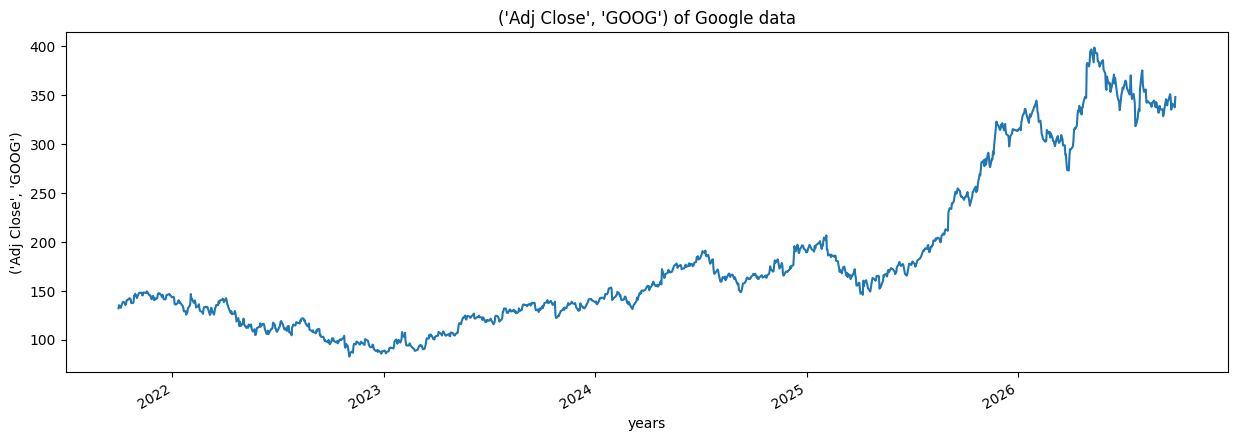

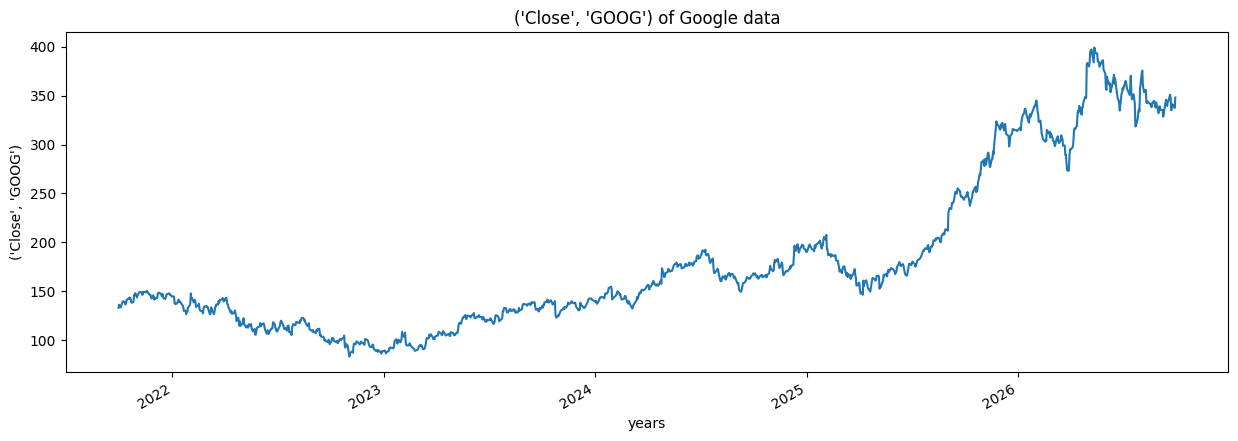

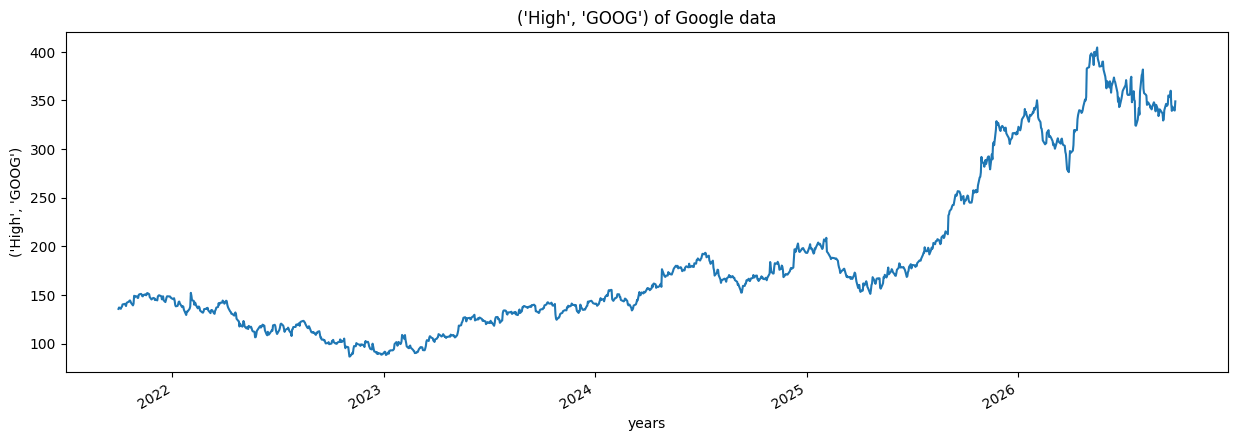

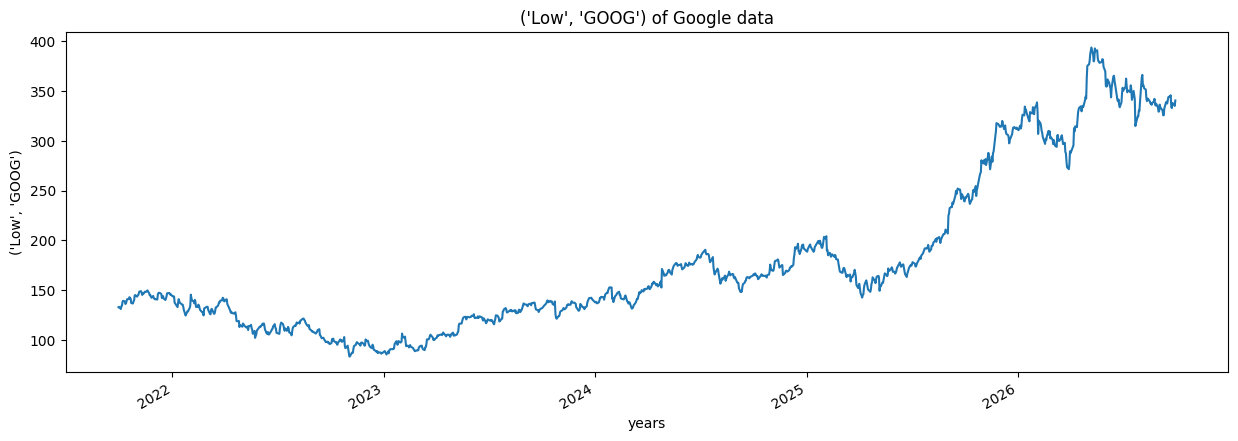

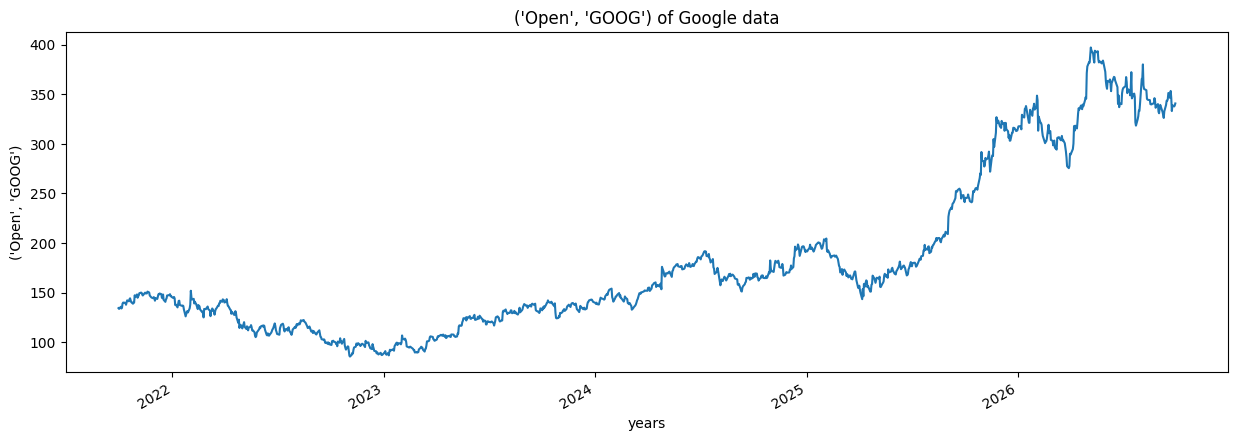

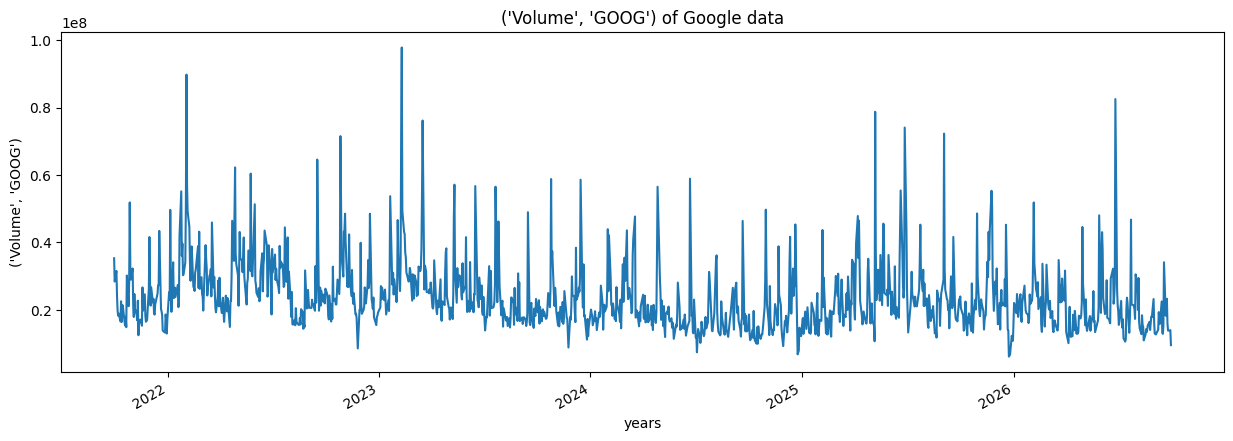

In [64]:
for column in google_data.columns:
    plot_graph((15,5), google_data[column], column)

In [65]:
temp_data=[10,20,30,40,50,60,70,80,90,100]
print(sum(temp_data[1:6])/5)

40.0


In [66]:
import pandas as pd
data=pd.DataFrame([10,20,30,40,50,60,70,80,90,100])
data.head()

,0
0,10
1,20
2,30
3,40
4,50


In [67]:
data['MA'] = data[0].rolling(5).mean()

In [68]:
data

,0,MA
0,10,NaN
1,20,NaN
2,30,NaN
3,40,NaN
4,50,30.0
5,60,40.0
6,70,50.0
7,80,60.0
8,90,70.0
9,100,80.0


In [69]:
for i in range(2004,2027):
  print(i,list(google_data.index.year).count(i))

2004 0
2005 0
2006 0
2007 0
2008 0
2009 0
2010 0
2011 0
2012 0
2013 0
2014 0
2015 0
2016 0
2017 0
2018 0
2019 0
2020 0
2021 65
2022 251
2023 250
2024 252
2025 250
2026 187


In [70]:
google_data['MA_for_250_days']=google_data['Adj Close'].rolling(250).mean()

In [71]:
google_data['MA_for_250_days'][0:250].tail()

,MA_for_250_days
Date,
2022-09-21,NaN
2022-09-22,NaN
2022-09-23,NaN
2022-09-26,NaN
2022-09-27,126.756412


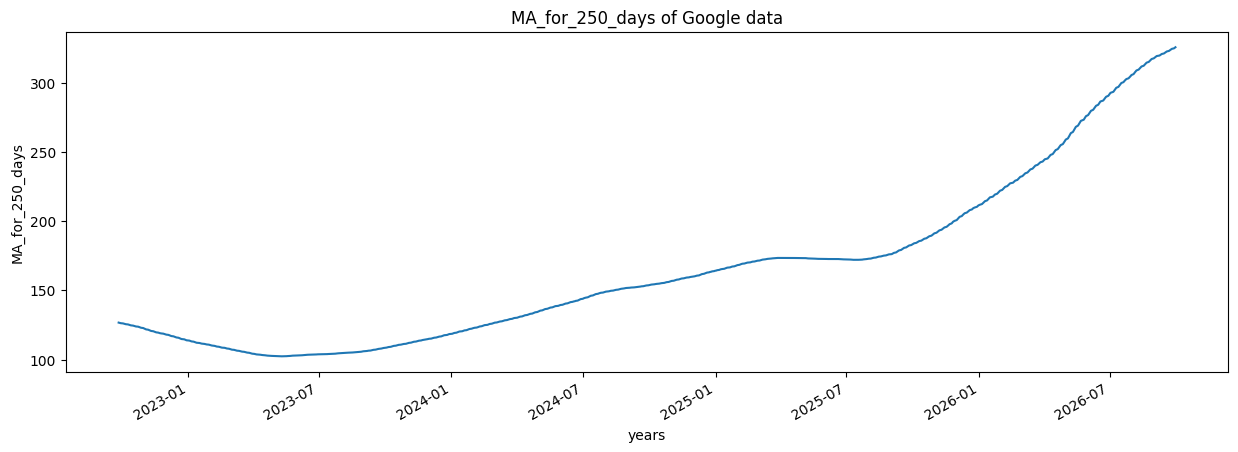

In [72]:
plot_graph((15,5),google_data['MA_for_250_days'],'MA_for_250_days')

<Figure size 640x480 with 0 Axes>

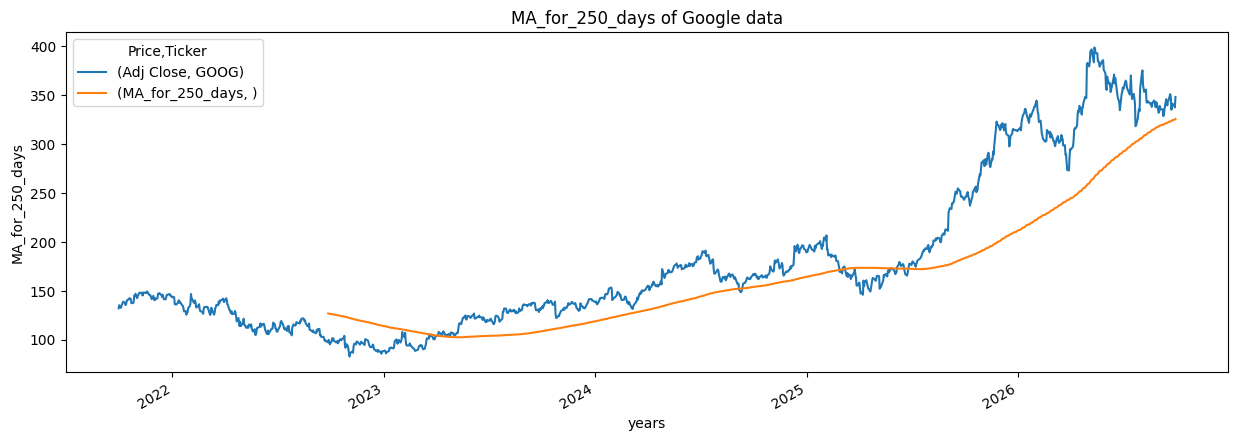

In [73]:
plot_graph((15,5),google_data[['Adj Close', 'MA_for_250_days']],'MA_for_250_days')

<Figure size 640x480 with 0 Axes>

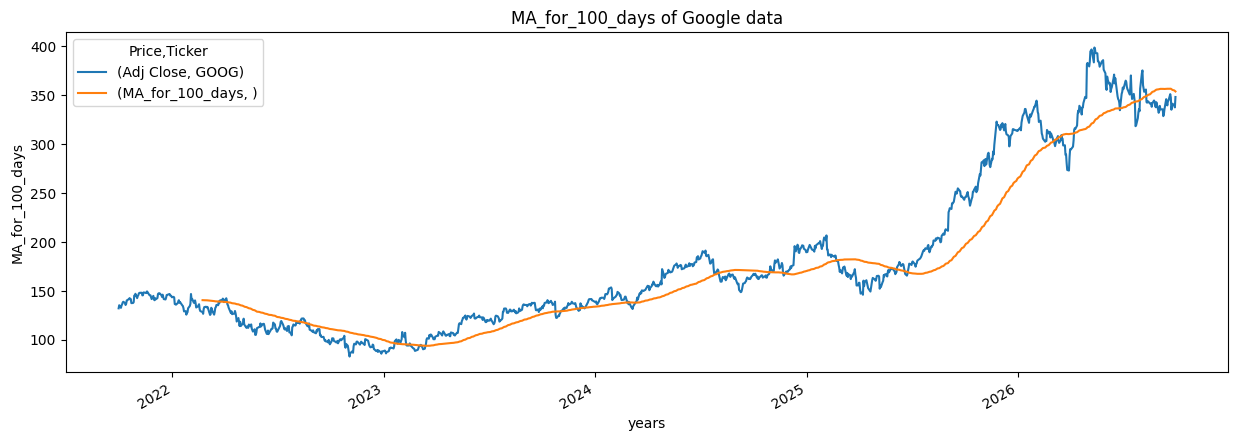

In [74]:
google_data['MA_for_100_days']=google_data['Adj Close'].rolling(100).mean()
plot_graph((15,5),google_data[['Adj Close','MA_for_100_days']],'MA_for_100_days')


<Figure size 640x480 with 0 Axes>

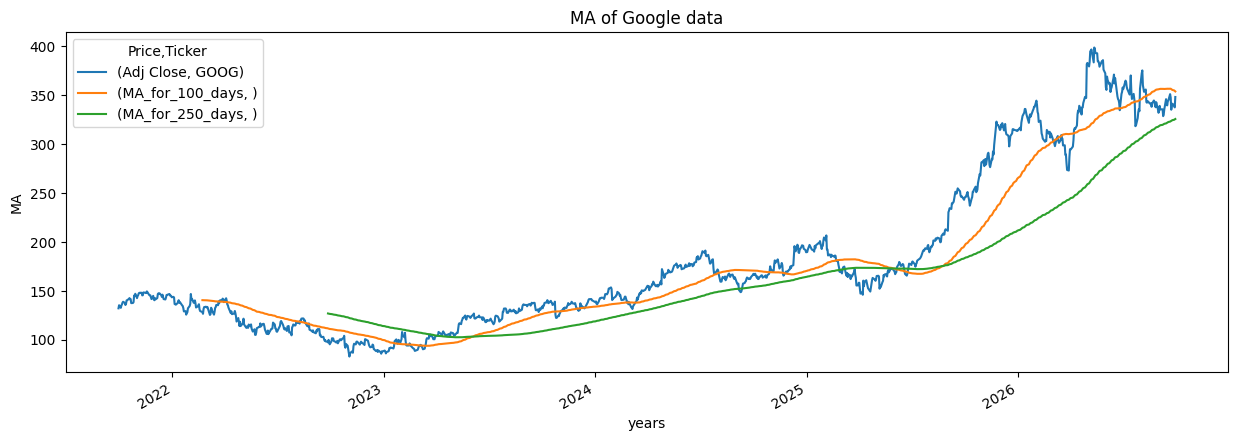

In [75]:
plot_graph((15,5),google_data[['Adj Close','MA_for_100_days','MA_for_250_days']],'MA')

In [76]:
google_data['percentage_change_cp']=google_data['Adj Close'].pct_change()
google_data[['Adj Close','percentage_change_cp']].head()

Price,Adj Close,percentage_change_cp
Ticker,GOOG,
Date,,
2021-09-30,132.015106,NaN
2021-10-01,135.182114,0.023990
2021-10-04,132.509918,-0.019767
2021-10-05,134.899277,0.018032
2021-10-06,136.065247,0.008643


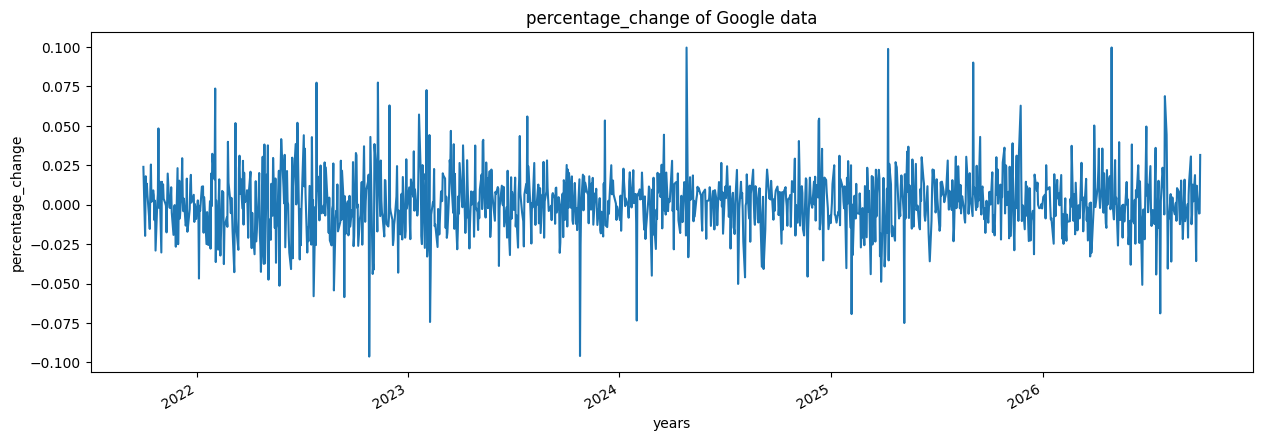

In [77]:
plot_graph((15,5),google_data['percentage_change_cp'],'percentage_change')

In [78]:
Adj_Close_price=google_data[['Adj Close']]

In [79]:
max(Adj_Close_price.values),min(Adj_Close_price.values)

(array([398.54125977]), array([82.70662689]))

In [80]:
from sklearn.preprocessing import MinMaxScaler

scaler=MinMaxScaler(feature_range=(0,1))
scaled_data=scaler.fit_transform(Adj_Close_price)
scaled_data

array([[0.15612119],
       [0.16614861],
       [0.15768787],
       ...,
       [0.81198624],
       [0.80616042],
       [0.83984889]])

In [81]:
len(scaled_data)

1255

In [82]:
x_data=[]
y_data=[]

for i in range(100,len(scaled_data)):
  x_data.append(scaled_data[i-100:i])
  y_data.append(scaled_data[i])

import numpy as np
x_data,y_data=np.array(x_data),np.array(y_data)


In [83]:
x_data[0],y_data[0]

(array([[0.15612119],
        [0.16614861],
        [0.15768787],
        [0.16525309],
        [0.1689448 ],
        [0.17468927],
        [0.1774196 ],
        [0.17362919],
        [0.16693427],
        [0.17065729],
        [0.18167271],
        [0.18249764],
        [0.18652962],
        [0.18923169],
        [0.18481868],
        [0.18596499],
        [0.17293127],
        [0.17339545],
        [0.17621527],
        [0.19740387],
        [0.19646766],
        [0.20318447],
        [0.1890811 ],
        [0.1956334 ],
        [0.19854081],
        [0.20447828],
        [0.2062285 ],
        [0.20657495],
        [0.20625198],
        [0.19802652],
        [0.19840911],
        [0.20749704],
        [0.2066895 ],
        [0.20571092],
        [0.20566701],
        [0.21083278],
        [0.20846006],
        [0.1994458 ],
        [0.19843737],
        [0.19831345],
        [0.186045  ],
        [0.19642056],
        [0.18493463],
        [0.18231879],
        [0.18908893],
        [0

In [84]:
int(len(x_data)*0.7)

808

In [85]:
4908-100-int(len(x_data)*0.7)

4000

In [86]:
splitting_len=int(len(x_data)*0.7)
x_train=x_data[:splitting_len]
y_train=y_data[:splitting_len]

x_test=x_data[splitting_len:]
y_test=y_data[splitting_len:]



In [87]:
print(x_train.shape)
print(y_train.shape)
print(x_test.shape)
print(y_test.shape)

(808, 100, 1)
(808, 1)
(347, 100, 1)
(347, 1)


In [88]:
from keras.models import Sequential
from keras.layers import Dense, LSTM

In [91]:
model=Sequential()
model.add(LSTM(128,return_sequences=True,input_shape=(x_train.shape[1],1)))

model.add(LSTM(64,return_sequences=False))
model.add(Dense(25))
model.add(Dense(1))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [92]:
model.compile(optimizer='adam',loss='mean_squared_error')

In [93]:
model.fit(x_train,y_train,batch_size=1,epochs=2)

Epoch 1/2
808/808 ━━━━━━━━━━━━━━━━━━━━ 44s 52ms/step - loss: 7.7595e-04
Epoch 2/2
808/808 ━━━━━━━━━━━━━━━━━━━━ 35s 44ms/step - loss: 3.5009e-04


In [94]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_3 (LSTM)                   │ (None, 100, 128)       │        66,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_4 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 25)             │         1,625 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 352,859 (1.35 MB)

 Trainable params: 117,619 (459.45 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 235,240 (918.91 KB)

In [95]:
predictions=model.predict(x_test)

11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step


In [96]:
predictions

array([[0.25346905],
       [0.2586664 ],
       [0.2645176 ],
       [0.27087185],
       [0.2766098 ],
       [0.27959397],
       [0.2834221 ],
       [0.28800067],
       [0.29073635],
       [0.29459894],
       [0.2979131 ],
       [0.3001292 ],
       [0.30134836],
       [0.30044326],
       [0.29717088],
       [0.29429802],
       [0.29233357],
       [0.29406273],
       [0.2989092 ],
       [0.3057772 ],
       [0.31172594],
       [0.31517738],
       [0.31621093],
       [0.317063  ],
       [0.31722048],
       [0.3151507 ],
       [0.30883348],
       [0.3006583 ],
       [0.2940061 ],
       [0.29137048],
       [0.29280433],
       [0.29816678],
       [0.30400154],
       [0.3088188 ],
       [0.31394666],
       [0.31873372],
       [0.32077768],
       [0.3197762 ],
       [0.31889844],
       [0.31875783],
       [0.32045418],
       [0.32355756],
       [0.3269457 ],
       [0.3302601 ],
       [0.33347952],
       [0.33677965],
       [0.34249923],
       [0.348

In [99]:
inv_predictions=scaler.inverse_transform(predictions)
inv_predictions

array([[162.76093],
       [164.40244],
       [166.25044],
       [168.25734],
       [170.0696 ],
       [171.0121 ],
       [172.22115],
       [173.66722],
       [174.53125],
       [175.75117],
       [176.79791],
       [177.49783],
       [177.88289],
       [177.59702],
       [176.56348],
       [175.65614],
       [175.0357 ],
       [175.58182],
       [177.1125 ],
       [179.28165],
       [181.16049],
       [182.25056],
       [182.57698],
       [182.84612],
       [182.89584],
       [182.24214],
       [180.24693],
       [177.66493],
       [175.56393],
       [174.73152],
       [175.18439],
       [176.87804],
       [178.72086],
       [180.24231],
       [181.86186],
       [183.37378],
       [184.01933],
       [183.70303],
       [183.4258 ],
       [183.3814 ],
       [183.91716],
       [184.89731],
       [185.9674 ],
       [187.0142 ],
       [188.031  ],
       [189.0733 ],
       [190.87975],
       [192.88596],
       [194.52034],
       [195.99258],


In [101]:
inv_y_test=scaler.inverse_transform(y_test)
inv_y_test

array([[166.02752686],
       [164.62413025],
       [166.6446228 ],
       [167.08255005],
       [164.54452515],
       [169.26226807],
       [171.17329407],
       [168.79446411],
       [173.16389465],
       [172.56671143],
       [172.14868164],
       [172.03919983],
       [169.5708313 ],
       [166.92330933],
       [168.59542847],
       [169.01347351],
       [174.0994873 ],
       [177.0092926 ],
       [179.38095093],
       [178.16523743],
       [176.35159302],
       [175.26541138],
       [177.31820679],
       [176.61068726],
       [173.37203979],
       [167.14389038],
       [165.42988586],
       [167.15385437],
       [170.89074707],
       [173.82048035],
       [177.64704895],
       [176.77012634],
       [176.29182434],
       [179.1318512 ],
       [179.91908264],
       [176.93952942],
       [174.54792786],
       [177.03919983],
       [178.07554626],
       [180.67642212],
       [182.1711731 ],
       [182.46017456],
       [183.12783813],
       [184

In [102]:
rmse=np.sqrt(np.mean(inv_predictions-inv_y_test)**2)

In [103]:
rmse

np.float64(1.0985544078288216)

In [105]:
ploting_data=pd.DataFrame(
    {
        'Original_test_data':inv_y_test.reshape(-1),
        'predictions'  :inv_predictions.reshape(-1)
    },
    index=google_data.index[splitting_len+100:]
)
ploting_data.head()

,Original_test_data,predictions
Date,,
2025-05-14,166.027527,162.760925
2025-05-15,164.624130,164.402435
2025-05-16,166.644623,166.250443
2025-05-19,167.082550,168.257339
2025-05-20,164.544525,170.069595


<Figure size 640x480 with 0 Axes>

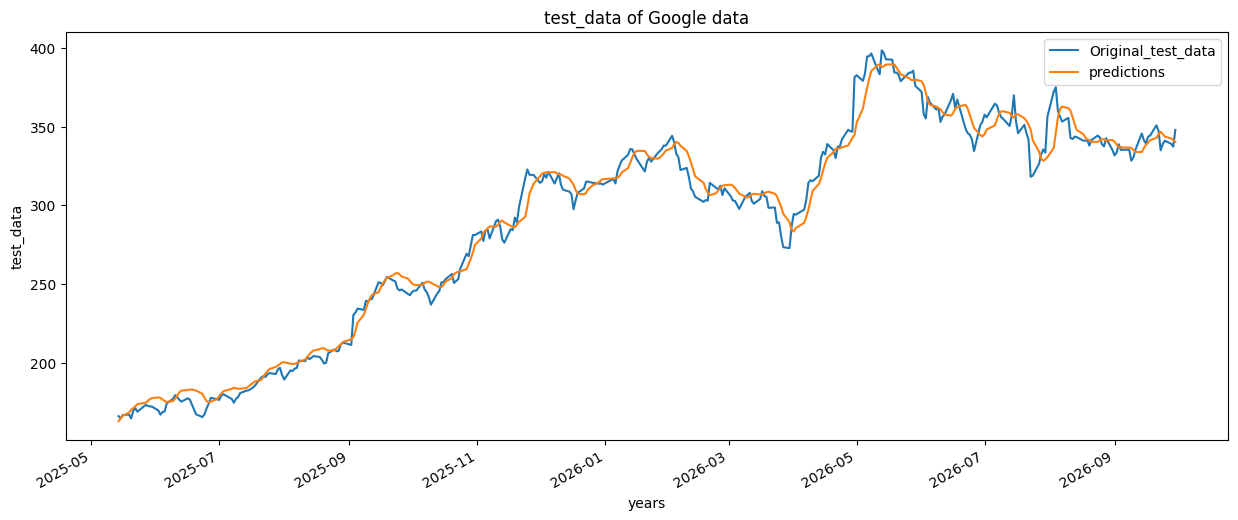

In [106]:
plot_graph((15,6),ploting_data,'test_data')

<Figure size 640x480 with 0 Axes>

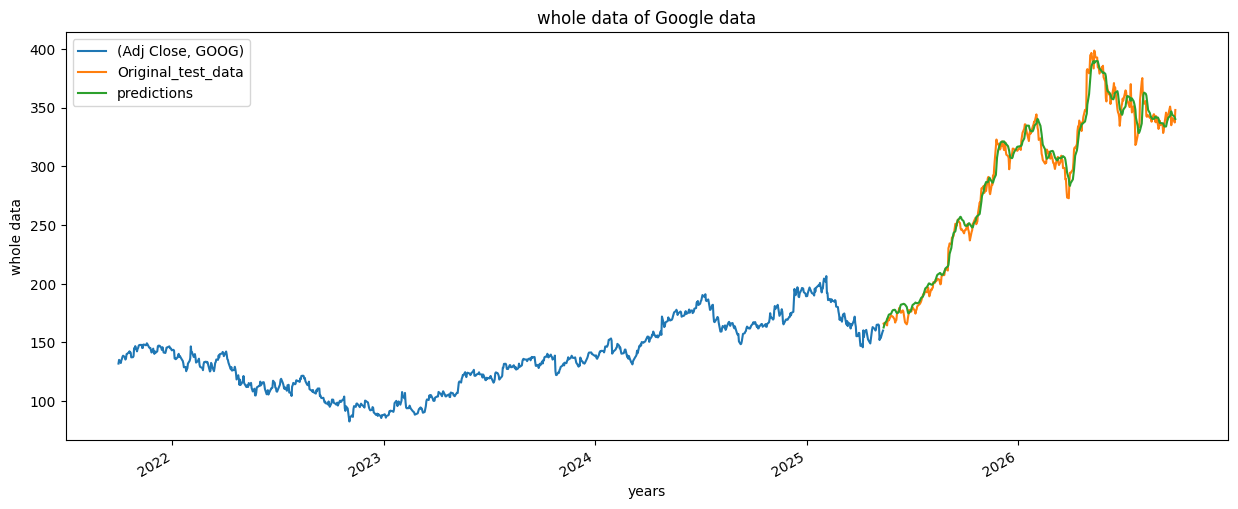

In [107]:
plot_graph((15,6),pd.concat([Adj_Close_price[:splitting_len+100],ploting_data],axis=0),'whole data')

In [108]:
model.save("Latest_stock_price_model.keras")